# HU-5 - Clustering de medicamentos con K-Means
**Objetivo:** agrupar automáticamente los medicamentos en perfiles o tipologías con un modelo K-Means (scikit-learn), interpretar cada grupo y ponerle nombre.

**Decisiones de diseño**
- **Variables del modelo:** solo las continuas (3 métricas de la ficha técnica, precio y antigüedad). Las binarias no entran en el modelo: se usan después para describir y nombrar los clusters. En las pruebas, al incluirlas, el modelo se limitaba a separar inyectables de no inyectables y creaba grupos de 8 a 12 medicamentos por variables muy desbalanceadas.
- **Precio nulo:** los medicamentos sin precio (biológicos de uso hospitalario) se rellenan con 0. Así, "no tener precio en farmacia" pasa a ser un rasgo que ayuda a separar ese perfil.
- **Número de clusters:** se elige combinando el método del codo, el coeficiente de silueta y la interpretabilidad de los grupos.

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

## 1. Carga de datos

In [4]:
RUTA_MODELO = "../datos/medicamentos_artritis_reumatoide_modelo.xlsx"
RUTA_COMPLETO = "../datos/medicamentos_artritis_reumatoide_hu4.xlsx"

# nregistro se lee como texto para no perder los ceros a la izquierda
df = pd.read_excel(RUTA_MODELO, dtype={"nregistro": str})

print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
df.head()

Filas: 645 | Columnas: 32


,nregistro,nombre,volumen_informativo_seguridad,complejidad_desglose_clinico,indicador_riesgo_severo,pvp_iva,dosis_mg,antiguedad_anios,num_principios_activos,comercializado,generico,biosimilar,afecta_conduccion,triangulo_negro,tratamiento_larga_duracion,tiene_precio,tiene_revision,inyectable,estado_alta,estado_baja,via_intraarticular,via_intramuscular,via_intravenosa,via_oral,via_rectal,via_subcutanea,via_otras,forma_inyectable,forma_oral_liquido,forma_oral_solido,forma_perfusion,forma_rectal
0,61836,ACABEL 4 mg COMPRIMIDOS RECUBIERTOS CON PELICULA,1318,1,6,2.50,4.0,28.5,1,0,0,0,0,0,0.0,1,1,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0
1,61837,ACABEL 8 mg COMPRIMIDOS RECUBIERTOS CON PELICULA,1319,1,6,4.51,8.0,28.5,1,0,0,0,0,0,0.0,1,1,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0
2,69223,ACECLOFENACO CINFA 100 mg COMPRIMIDOS RECUBIER...,1127,1,8,2.83,100.0,19.2,1,1,1,0,0,0,0.0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0
3,71437,ACECLOFENACO NORMON 100 mg COMPRIMIDOS RECUBIE...,1124,1,8,2.83,100.0,17.1,1,1,1,0,0,0,0.0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0
4,79696,ACECLOFENACO STADA 100 MG COMPRIMIDOS RECUBIER...,1100,1,9,2.83,100.0,11.6,1,1,1,0,0,0,0.0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0


In [5]:
# Del fichero completo las columnas descriptivasno entran en el modelo 
# Se usan más adelante para interpretar y nombrar los clusters
df_info = pd.read_excel(RUTA_COMPLETO, dtype={"nregistro": str},
                        usecols=["nregistro", "pactivos", "forma_agrupada", "labtitular"])
df = df.merge(df_info, on="nregistro", how="left")

In [ ]:
# Columnas con valores nulos
df.isna().sum()[lambda s: s > 0]

pvp_iva                       156
dosis_mg                        5
tratamiento_larga_duracion    306
dtype: int64

## 2. Preparación de variables
Variables:
- `volumen_informativo_seguridad`: Palabras de la sección 4.4 (advertencias y precauciones) 
- `complejidad_desglose_clinico`: Número de tablas en la ficha técnica 
- `indicador_riesgo_severo`: Menciones de "grave" en la ficha técnica 
- `pvp_iva`: Precio de venta al público con IVA 
- `antiguedad_anios`: Años desde la autorización

Cambios a realizar:
- **Nulos del precio = 0**: medicamentos sin precio en farmacia.
- **Transformación logarítmica (`log1p`)** en las métricas y el precio: tienen mucha asimetría y valores extremos. K-Means es sensible a ellos porque trabaja con distancias.
- **Estandarización (`StandardScaler`)**: todas las variables pasan a media 0 y desviación 1, para que ninguna tenga mucha importancia en el modelo solo por tener una escala mayor.

In [ ]:
variables_modelo = ["volumen_informativo_seguridad", "complejidad_desglose_clinico",
                    "indicador_riesgo_severo", "pvp_iva", "antiguedad_anios"]

X = df[variables_modelo].copy()

# Precio nulo = 0
print("Precios nulos rellenados con 0:", X["pvp_iva"].isna().sum())
X["pvp_iva"] = X["pvp_iva"].fillna(0)

X.describe()

Precios nulos rellenados con 0: 156


,volumen_informativo_seguridad,complejidad_desglose_clinico,indicador_riesgo_severo,pvp_iva,antiguedad_anios
count,645.000000,645.000000,645.00000,645.00000,645.000000
mean,1585.730233,4.341085,20.04186,9.34245,15.642326
std,634.228784,8.055221,17.86439,14.68461,12.510291
min,244.000000,0.000000,0.00000,0.00000,0.200000
25%,1084.000000,0.000000,11.00000,1.65000,8.100000
50%,1536.000000,1.000000,16.00000,2.67000,11.300000
75%,1855.000000,3.000000,18.00000,13.49000,19.300000
max,3927.000000,38.000000,114.00000,167.48000,68.800000


In [ ]:
# Transformación logarítmica
variables_log = ["volumen_informativo_seguridad", "complejidad_desglose_clinico",
                 "indicador_riesgo_severo", "pvp_iva"]
X_log = X.copy()
X_log[variables_log] = np.log1p(X_log[variables_log])

Asimetría antes y después de log1p:


,antes,despues
volumen_informativo_seguridad,0.93,-0.74
complejidad_desglose_clinico,2.57,1.03
indicador_riesgo_severo,2.77,0.32
pvp_iva,4.89,0.18
antiguedad_anios,1.98,1.98


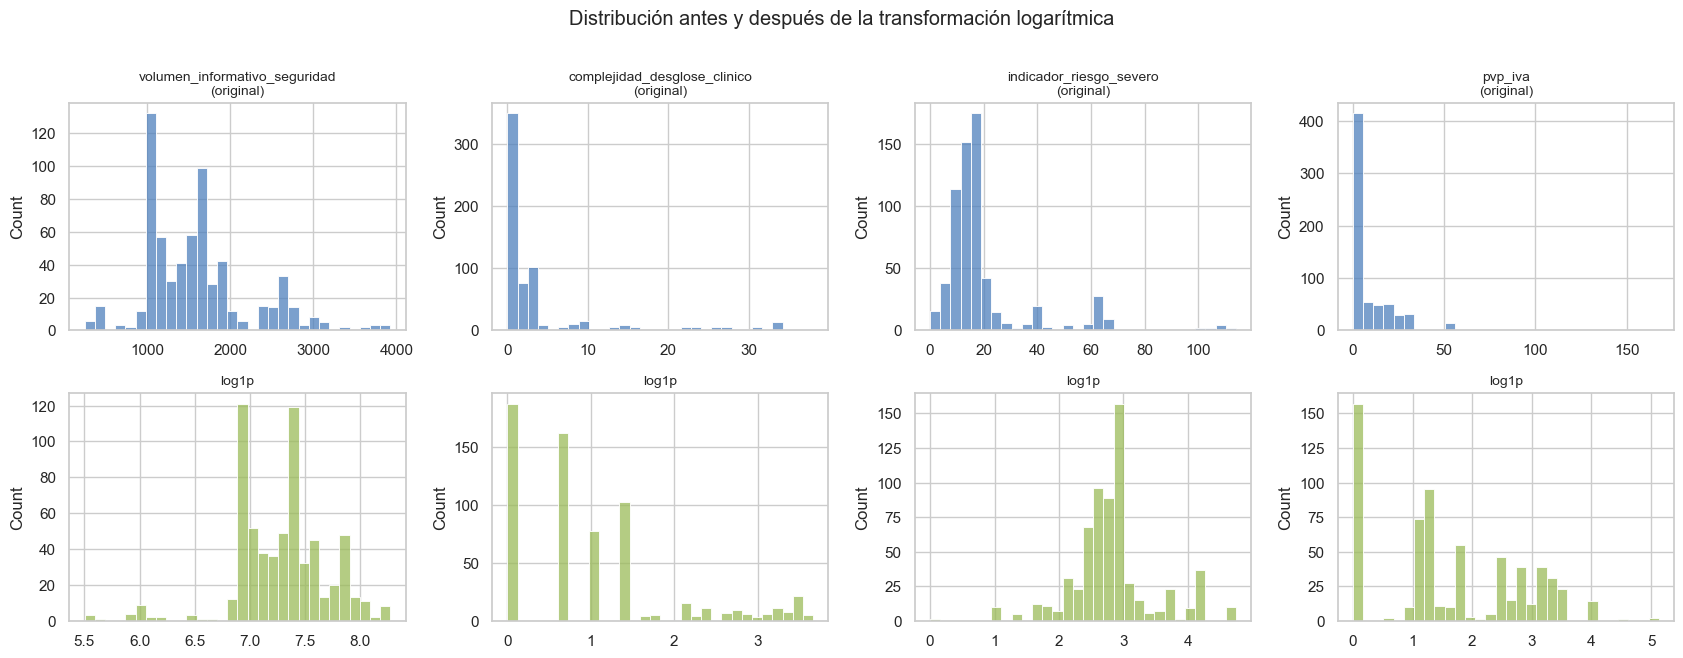

In [15]:
# Distribuciones antes y después de la tranformación para analizarlo
fig, axes = plt.subplots(2, 4, figsize=(17, 6.5))
for i, col in enumerate(variables_log):
    sns.histplot(X[col], bins=30, ax=axes[0, i], color="#4f81bd")
    axes[0, i].set_title(f"{col}\n(original)", fontsize=10); axes[0, i].set_xlabel("")
    sns.histplot(X_log[col], bins=30, ax=axes[1, i], color="#9bbb59")
    axes[1, i].set_title("log1p", fontsize=10); axes[1, i].set_xlabel("")
plt.suptitle("Distribución antes y después de la transformación logarítmica", y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
# Estandarización de los datos numéricos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

pd.DataFrame(X_scaled, columns=variables_modelo).describe().T[["mean", "std"]]

,mean,std
volumen_informativo_seguridad,9.033256e-16,1.000776
complejidad_desglose_clinico,2.203233e-17,1.000776
indicador_riesgo_severo,1.101617e-16,1.000776
pvp_iva,7.573614e-17,1.000776
antiguedad_anios,8.812933e-17,1.000776


# 3. Elección del número de clusters
En esta sección se entrena K-Means para los valores de k (clusters) entre 2 y 10 y se comparan los siguientes criterios:
- **Método del codo**: suma de distancias al cuadrado de cada punto a su centroide. Siempre baja al aumentar k; se busca el punto donde deja de bajar de forma notable.
- **Coeficiente de silueta**: mide si cada medicamento está más cerca de su cluster que del siguiente más cercano (de -1 a 1; cuanto más alto, mejor separados).

In [21]:
rango_k = range(2, 11)
codo = []
siluetas = []

for k in rango_k:
    kmeans_k = KMeans(n_clusters=k, n_init=20, random_state=42)
    etiquetas_k = kmeans_k.fit_predict(X_scaled)
    codo.append(kmeans_k.inertia_)
    siluetas.append(silhouette_score(X_scaled, etiquetas_k))

resultados_k = pd.DataFrame({"k": list(rango_k), "codo": codo, "silueta": siluetas})
resultados_k

,k,codo,silueta
0,2,2007.220999,0.462463
1,3,1470.629096,0.349982
2,4,1173.007531,0.347405
3,5,918.242044,0.382194
4,6,734.665300,0.417215
5,7,654.048286,0.404707
6,8,589.004860,0.383690
7,9,535.700410,0.386613
8,10,492.633081,0.381150


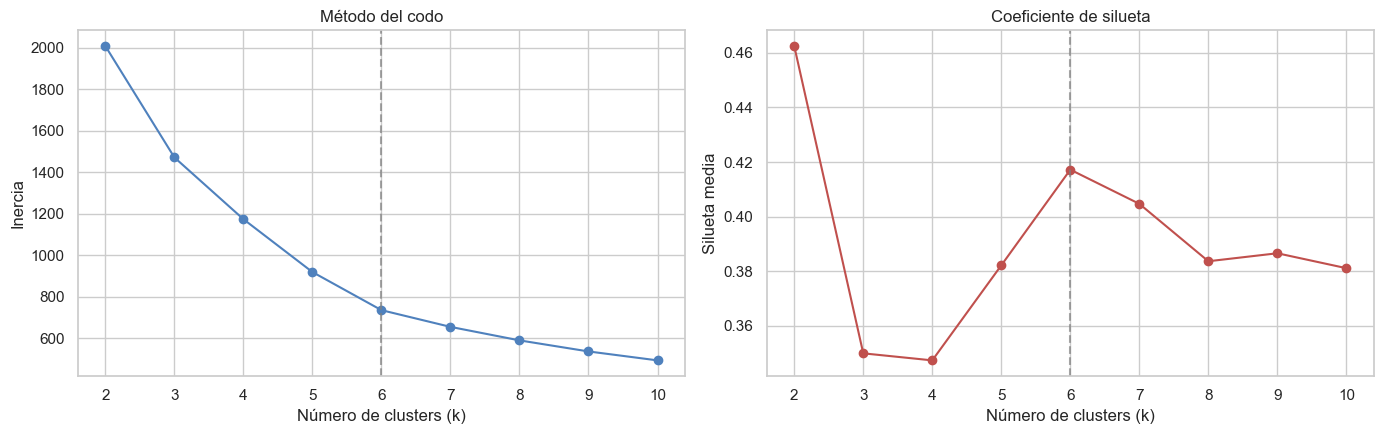

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(resultados_k["k"], resultados_k["codo"], "o-", color="#4f81bd")
axes[0].set_title("Método del codo")
axes[0].set_xlabel("Número de clusters (k)"); axes[0].set_ylabel("Inercia")

axes[1].plot(resultados_k["k"], resultados_k["silueta"], "o-", color="#c0504d")
axes[1].set_title("Coeficiente de silueta")
axes[1].set_xlabel("Número de clusters (k)"); axes[1].set_ylabel("Silueta media")

for ax in axes:
    ax.axvline(6, color="grey", ls="--", alpha=0.7)
    ax.set_xticks(list(rango_k))
plt.tight_layout()
plt.show()

#### Conclusiones de resultados:
**Elección: k = 6**

- **k = 2** tiene la silueta más alta, pero solo separa los biológicos del resto: no aporta perfiles nuevos.
- Entre k = 3 y k = 10, la silueta alcanza su máximo en **k = 6** (alrededor de 0,42). A partir de ahí la inercia baja cada vez menos (el codo se aplana).

## 4. Entrenamiento del modelo

In [24]:
K = 6
kmeans = KMeans(n_clusters=K, n_init=20, random_state=42)
df["cluster"] = kmeans.fit_predict(X_scaled)

print(f"Silueta media con k={K}: {silhouette_score(X_scaled, df['cluster']):.3f}")
df["cluster"].value_counts().sort_index().to_frame("n_medicamentos")

Silueta media con k=6: 0.417


,n_medicamentos
cluster,
0,159
1,185
2,101
3,56
4,26
5,118


## 5. Análisis de los clusters
Conviene analizar los datos de los valores dentro de cada cluster antes de la transformación.

In [26]:
# Media de las variables del modelo antes de escalarlos
perfil = df.groupby("cluster")[variables_modelo].mean().round(1)
perfil["sin_precio_%"] = (df["pvp_iva"].isna().groupby(df["cluster"]).mean() * 100)
perfil["n"] = df["cluster"].value_counts().sort_index()
perfil

,volumen_informativo_seguridad,complejidad_desglose_clinico,indicador_riesgo_severo,pvp_iva,antiguedad_anios,sin_precio_%,n
cluster,,,,,,,
0,1067.0,2.5,15.9,12.3,10.7,0.000000,159
1,1497.0,0.7,12.7,2.4,15.2,24.864865,185
2,2556.0,20.1,54.1,NaN,8.8,100.000000,101
3,1421.2,0.7,9.5,3.8,47.8,10.714286,56
4,438.6,0.5,3.3,2.9,20.7,11.538462,26
5,1924.2,1.6,16.7,29.5,12.4,0.000000,118


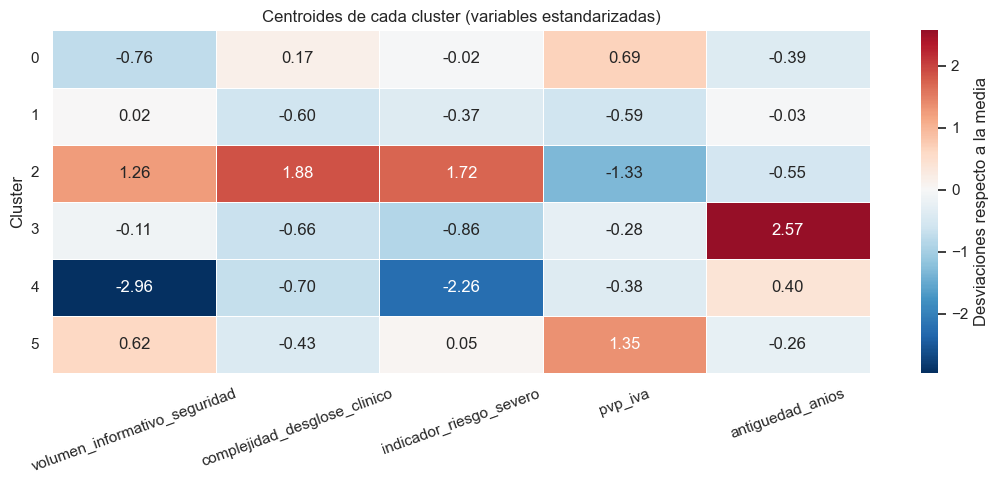

In [27]:
# Cuánto se aleja cada cluster de la media (0) en cada variable
centroides = pd.DataFrame(kmeans.cluster_centers_, columns=variables_modelo)

fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(centroides, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.5, ax=ax,
            cbar_kws={"label": "Desviaciones respecto a la media"})
ax.set_title("Centroides de cada cluster (variables estandarizadas)")
ax.set_ylabel("Cluster")
ax.tick_params(axis="x", rotation=20)
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

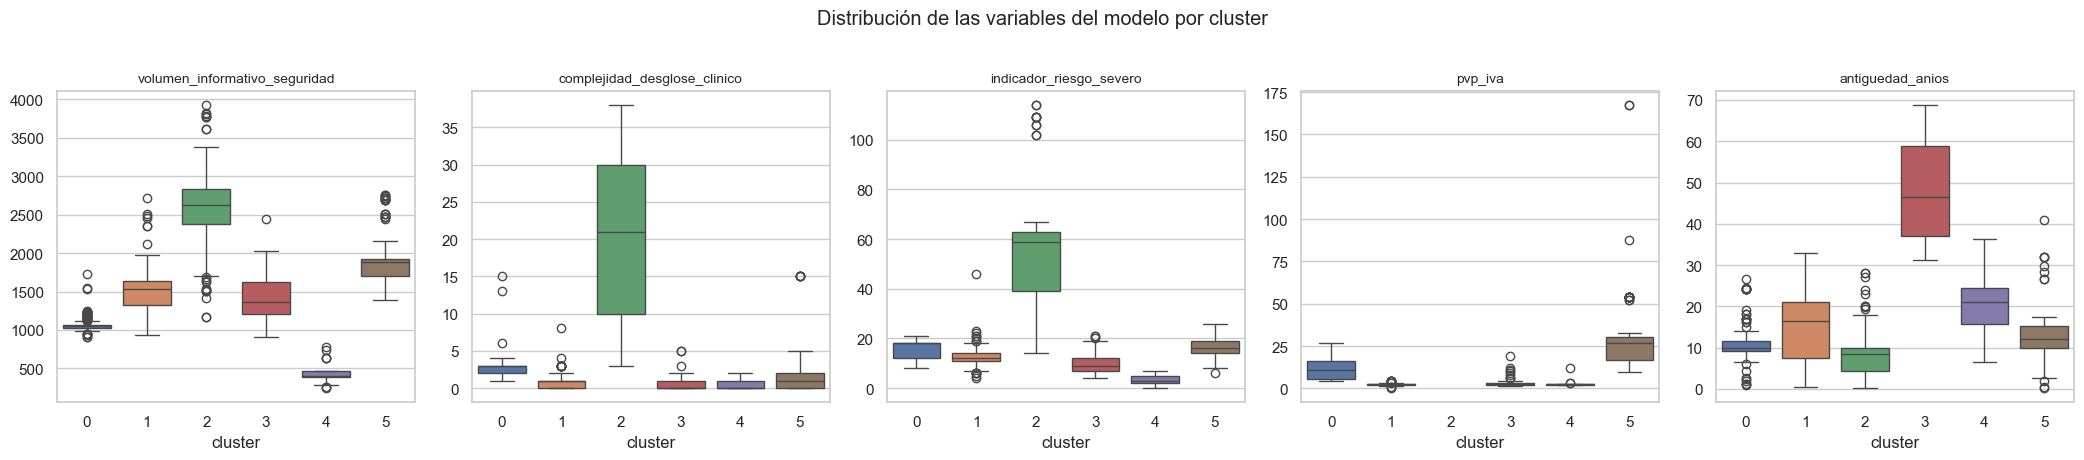

In [34]:
# Distribución de las variables dentro de cada cluster
fig, axes = plt.subplots(1, 5, figsize=(21, 4.5))
for ax, col in zip(axes, variables_modelo):
    sns.boxplot(data=df, x="cluster", y=col, ax=ax, hue="cluster", palette="deep", legend=False)
    ax.set_title(col, fontsize=10); ax.set_ylabel("")
plt.suptitle("Distribución de las variables del modelo por cluster", y=1.02)
plt.tight_layout()
plt.show()

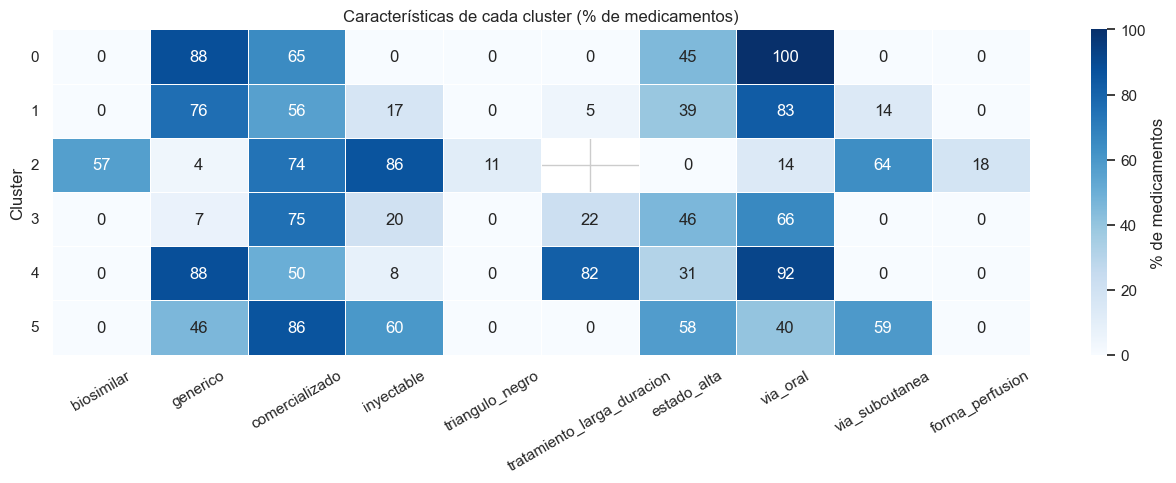

In [29]:
binarias_descripcion = ["biosimilar", "generico", "comercializado", "inyectable", "triangulo_negro",
                        "tratamiento_larga_duracion", "estado_alta", "via_oral", "via_subcutanea", "forma_perfusion"]

descripcion = (df.groupby("cluster")[binarias_descripcion].mean() * 100).round(0)

fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(descripcion, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, linewidths=0.5, ax=ax,
            cbar_kws={"label": "% de medicamentos"})
ax.set_title("Características de cada cluster (% de medicamentos)")
ax.set_ylabel("Cluster")
ax.tick_params(axis="x", rotation=30)
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

Las variables binarias no se han usado para entrenar el modelo, pero ayudan a describir cada grupo: se muestra el porcentaje de medicamentos de cada cluster que cumple cada característica. Las celdas vacías indican que no hay dato (por ejemplo, `tratamiento_larga_duracion` en los medicamentos que no cruzaron con el Nomenclátor).


In [35]:
# Principios activos y formas farmacéuticas más frecuentes en cada cluster
for c in range(K):
    grupo = df[df["cluster"] == c]
    print(f"\n▶ Cluster {c} ({len(grupo)} medicamentos)")
    print("  Principios activos:", grupo["pactivos"].value_counts().head(6).to_dict())
    print("  Formas:            ", grupo["forma_agrupada"].value_counts().to_dict())


▶ Cluster 0 (159 medicamentos)
  Principios activos: {'ETORICOXIB': 112, 'CELECOXIB': 31, 'HIDROXICLOROQUINA SULFATO': 10, 'DEXAMETASONA': 5, 'LEFLUNOMIDA': 1}
  Formas:             {'ORAL SOLIDO': 159}

▶ Cluster 1 (185 medicamentos)
  Principios activos: {'IBUPROFENO': 75, 'MELOXICAM': 16, 'DICLOFENACO SODICO': 13, 'METOTREXATO DISODIO': 12, 'METOTREXATO': 10, 'ACECLOFENACO': 9}
  Formas:             {'ORAL SOLIDO': 120, 'ORAL LIQUIDO': 33, 'INYECTABLE': 32}

▶ Cluster 2 (101 medicamentos)
  Principios activos: {'ADALIMUMAB': 33, 'ETANERCEPT': 12, 'TOCILIZUMAB': 11, 'RITUXIMAB': 10, 'INFLIXIMAB': 8, 'TOFACITINIB CITRATO': 5}
  Formas:             {'INYECTABLE': 69, 'PERFUSION': 18, 'ORAL SOLIDO': 14}

▶ Cluster 3 (56 medicamentos)
  Principios activos: {'DICLOFENACO SODICO': 12, 'INDOMETACINA': 9, 'ACECLOFENACO': 4, 'KETOPROFENO': 4, 'PIROXICAM': 3, 'PREDNISONA': 3}
  Formas:             {'ORAL SOLIDO': 34, 'INYECTABLE': 11, 'RECTAL': 8, 'ORAL LIQUIDO': 3}

▶ Cluster 4 (26 medicamen

## 6. Nombrar los Clusters
| Título | Explicación |
|---|---|
| **Biológicos y terapias dirigidas** | Cluster con más medicamentos sin precio |
| **Clásicos de larga trayectoria** | Cluster con mayor antigüedad media |
| **Fichas breves (corticoides y analgésicos)** | Cluster con menor volumen de la sección 4.4 |
| **AINE genéricos económicos** | De los tres restantes, el de precio medio más bajo |
| **FAME e inmunosupresores** | De los dos restantes, el de mayor volumen de la sección 4.4 |
| **Coxibs (antiinflamatorios selectivos)** | El último cluster |

In [ ]:
pendientes = perfil.copy()
nombres_cluster = {}

c_bio = pendientes["sin_precio_%"].idxmax()
nombres_cluster[c_bio] = "Biológicos y terapias dirigidas"
pendientes = pendientes.drop(c_bio)

c_clasicos = pendientes["antiguedad_anios"].idxmax()
nombres_cluster[c_clasicos] = "Clásicos de larga trayectoria"
pendientes = pendientes.drop(c_clasicos)

c_breves = pendientes["volumen_informativo_seguridad"].idxmin()
nombres_cluster[c_breves] = "Fichas breves (corticoides y analgésicos)"
pendientes = pendientes.drop(c_breves)

c_aine = pendientes["pvp_iva"].idxmin()
nombres_cluster[c_aine] = "AINE genéricos económicos"
pendientes = pendientes.drop(c_aine)

c_fame = pendientes["volumen_informativo_seguridad"].idxmax()
nombres_cluster[c_fame] = "FAME e inmunosupresores"
pendientes = pendientes.drop(c_fame)

nombres_cluster[pendientes.index[0]] = "Coxibs (antiinflamatorios selectivos)"

df["nombre_cluster"] = df["cluster"].map(nombres_cluster)

# Reasignar los colores usados en los apartados anteriores
colores_cluster = {nombres_cluster[c]: sns.color_palette("deep")[c] for c in range(K)}

perfil_nombrado = perfil.copy()
perfil_nombrado.insert(0, "nombre_cluster", perfil_nombrado.index.map(nombres_cluster))
perfil_nombrado

,nombre_cluster,volumen_informativo_seguridad,complejidad_desglose_clinico,indicador_riesgo_severo,pvp_iva,antiguedad_anios,sin_precio_%,n
cluster,,,,,,,,
0,Coxibs (antiinflamatorios selectivos),1067.0,2.5,15.9,12.3,10.7,0.000000,159
1,AINE genéricos económicos,1497.0,0.7,12.7,2.4,15.2,24.864865,185
2,Biológicos y terapias dirigidas,2556.0,20.1,54.1,NaN,8.8,100.000000,101
3,Clásicos de larga trayectoria,1421.2,0.7,9.5,3.8,47.8,10.714286,56
4,Fichas breves (corticoides y analgésicos),438.6,0.5,3.3,2.9,20.7,11.538462,26
5,FAME e inmunosupresores,1924.2,1.6,16.7,29.5,12.4,0.000000,118


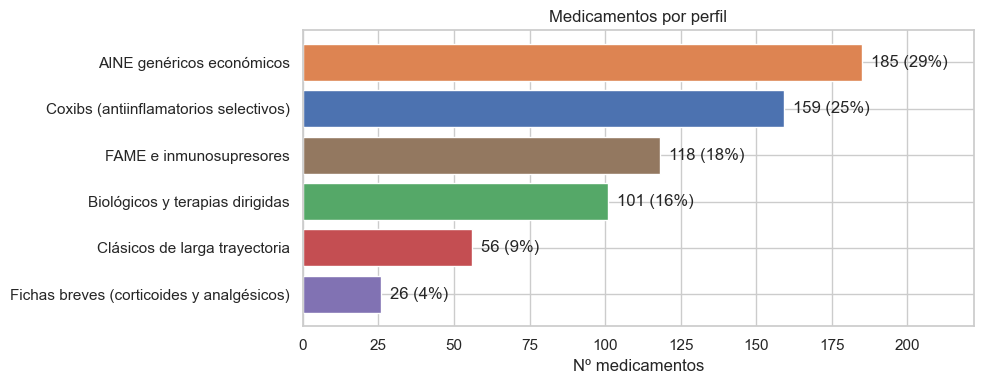

In [37]:
orden_clusters = perfil_nombrado.sort_values("n", ascending=False)["nombre_cluster"].tolist()

fig, ax = plt.subplots(figsize=(10, 4))
conteo = df["nombre_cluster"].value_counts().reindex(orden_clusters)
ax.barh(conteo.index, conteo.values, color=[colores_cluster[n] for n in conteo.index])
for i, v in enumerate(conteo.values):
    ax.text(v + 3, i, f"{v} ({v / len(df):.0%})", va="center")
ax.invert_yaxis()
ax.set_xlabel("Nº medicamentos")
ax.set_title("Medicamentos por perfil")
ax.set_xlim(0, conteo.max() * 1.2)
plt.tight_layout()
plt.show()

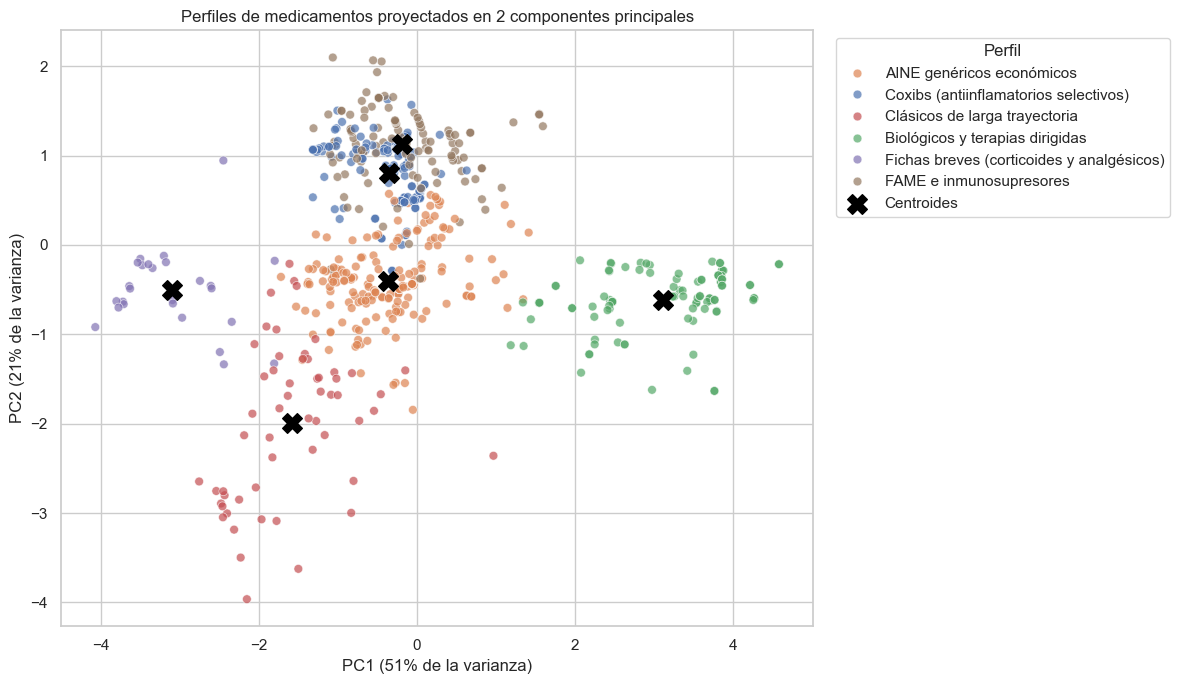

In [38]:
# Visualización con PCA (reduce las 5 variables a 2 componentes solo para poder dibujarlas)
pca = PCA(n_components=2, random_state=42)
componentes = pca.fit_transform(X_scaled)
centroides_pca = pca.transform(kmeans.cluster_centers_)

fig, ax = plt.subplots(figsize=(12, 7))
sns.scatterplot(x=componentes[:, 0], y=componentes[:, 1], hue=df["nombre_cluster"], palette=colores_cluster,
                alpha=0.7, s=40, ax=ax)
ax.scatter(centroides_pca[:, 0], centroides_pca[:, 1], c="black", marker="X", s=200, label="Centroides")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} de la varianza)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} de la varianza)")
ax.set_title("Perfiles de medicamentos proyectados en 2 componentes principales")
ax.legend(title="Perfil", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 7. Exportar resultados

In [39]:
RUTA_SALIDA = "../datos/medicamentos_artritis_reumatoide_clusters.csv"

# Quitar las columnas añadidas para analizar los clusters
df_salida = df.drop(columns=["pactivos", "forma_agrupada", "labtitular"])
df_salida.to_csv(RUTA_SALIDA, index=False, encoding="utf-8-sig")